## **CA2 Part B:**
### **Name: Cayden Sim**
### **Student ID: P2510893**
### **Class: DAAA/FT/1B/01**


---

## **Background Overview:**
- 397 days of data on energy consumption was collected. With each date representing the first day of each month from 1990 to 2022.
- The data includes:
    - Date
    - Gas Consumption (tons)
    - Electricity Consumption (MWh)
    - Water Consumption (tons)

## **Planned Workflow:**
-  ### Oveerall Workflow includes:
    - Data Exploration (EDA)
        - Understand data distribution, patterns and relationships
        - Identify potential outliers/anomalies
    - Preprocessing
        - Handle any missing values
        - Feature Engineering
    - Model Building and Implementation
        - Implement various models from Statsmodel library
    - Evaluation
        -  Model Comparison
            - Compare results across multiple forecasting models
            - Determine most suitable model that achieves the best results
    - Hyperparameter Tuning:
        - After finalising the model to use, conduct hyperparameter tuning in order to get the most optimal parameters that result in the most optimal results.


- ### **Libraries Used:**
    - **Data Manipulation & Numerical Operation**
        - pandas
        - numpy
    - **Machine Learning:**
        - scikit-learn
    - **Data Visualization**
        - matplotlib
        - Seaborn


## **Ultimate End Goal:**
The ultimate goal of this project is to forecast the total energy consumption (gas, electricity & water) for the next 60 months via training time series models




---
## **Step 1:** Importing Necessary Libraries and Modules

- Importing the required libraries as well as modules that are going to be used in this project.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

- Libraries added include:
    - pandas
    - numpy
    - matplotlib
    - seaborn
- **pandas** and **numpy** are used for data handling and analysis.
- **matplotlib** and **seaborn** are used to display visuals and graphs.

--- 
## **Step 2:** Loading Dataset's CSV File

- Import the downloaded dataset from the file explorer.

In [32]:
energy_df = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/AIML/CA2/CA2 Datasets/CA2-Energy-Consumption-Data.csv")

- Energy Consumption Data dataset is imported via pandas' **`.read_csv()`** method.
- Dataset is stored into a variable **`'energy_df'`**.

--- 
## **Step 3:** Exploratory Data Analysis **(EDA)**

- ### **Planned Overview**: 
    - Showcase dataset's information.

    - Check for missing data in columns. 

    - Identifying major outliers that can affect the output of the machine.

    - Visualize data spread with graphs.

    - Identifying any relationships between columns via pairplot/correlation heatmap

    - **Numerical Columns**: 

    - **Categorical Columns**: 

In [33]:
print("Here is a quick look at the DataFrame:")
energy_df

Here is a quick look at the DataFrame:


,DATE,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
0,1/1/1990,18.0,725.1,548.8
1,1/2/1990,15.8,706.7,640.7
2,1/3/1990,17.3,624.5,511.1
3,1/4/1990,18.9,574.7,515.3
4,1/5/1990,22.0,553.2,488.4
...,...,...,...,...
392,1/9/2022,27.7,986.2,513.3
393,1/10/2022,31.8,936.1,373.1
394,1/11/2022,31.0,973.4,343.9
395,1/12/2022,32.4,1147.2,348.3


- Here is how the DataFrame of energy consumption data looks like.

In [34]:
print("Here is the shape of the DataFrame: ", energy_df.shape)
energy_df.info()

Here is the shape of the DataFrame:  (397, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   DATE                           397 non-null    object 
 1   Gas Consumption (tons)         397 non-null    float64
 2   Electricity Consumption (MWh)  397 non-null    float64
 3   Water Consumption (tons)       397 non-null    float64
dtypes: float64(3), object(1)
memory usage: 12.5+ KB


- Using the **`.shape`** attribute and printing it shows that the customer dataset has **397 rows** and **4 columns**.
- Using the **`.info()`** method on the DataFrame prints its information.
    - From the output, it is shown that all rows are **`non-null`**, indicating that there are no empty data cells.
    - **`dtype`** shows the types of data in each column.

In [35]:
print("DataFrame Description:")
energy_df.describe()

DataFrame Description:


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
count,397.000000,397.000000,397.000000
mean,23.785139,888.472544,484.953652
std,4.903452,153.877594,133.908863
min,11.600000,553.200000,44.400000
25%,20.200000,771.100000,384.400000
50%,23.500000,897.800000,487.400000
75%,27.900000,1005.200000,580.200000
max,46.000000,1294.000000,811.000000


- The **`describe()`** summary provides an overview of key statistical properties such as the mean, standard deviation, and minimum/maximum values for each numerical feature. 

In [36]:
energy_df.isnull().sum()

DATE                             0
Gas Consumption (tons)           0
Electricity Consumption (MWh)    0
Water Consumption (tons)         0
dtype: int64

- Using the pandas' **'.isnull()'** method together with the **'.sum()'** method, it computes the total number of empty values within each column.
- The output above shows that all columns **'.isnull().sum()'** equate to **0**, indicating that there are no missing values in each column.

---
## **Step 3.5 - Continutinuation of EDA:** Plotting Visuals

- Some visuals will be plotted for better visualization and analysis of the original features.
- These visuals represents the relationship of each feature with another.

### **Mini Conversion Step:** Converting Data Column to Datetime Format **(Pre-Preprocessing)**
- Before we plot the visuals, convert the date column into a datetime format and set the index.
- This ensures that the dataset is treated as a proper time series.

In [37]:
energy_df['DATE'] = pd.to_datetime(energy_df['DATE'])
energy_df = energy_df.sort_values('DATE').set_index('DATE')

energy_df

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
DATE,,,
1990-01-01,18.0,725.1,548.8
1990-01-02,15.8,706.7,640.7
1990-01-03,17.3,624.5,511.1
1990-01-04,18.9,574.7,515.3
1990-01-05,22.0,553.2,488.4
...,...,...,...
2022-01-09,27.7,986.2,513.3
2022-01-10,31.8,936.1,373.1
2022-01-11,31.0,973.4,343.9


- Use pandas' '.to_datetime()' function to convert the dates in the DATE column into the datetime format. 
- After that, use .sort_values() and .set_index() and place 'DATE' inside the parenthesis.
- This ensures that the dates are ordered chronologically.
- This allows for easier graph plotting in the EDA portion.

**Not Preprocessing

## **Visual Representation 1:** Line Chart


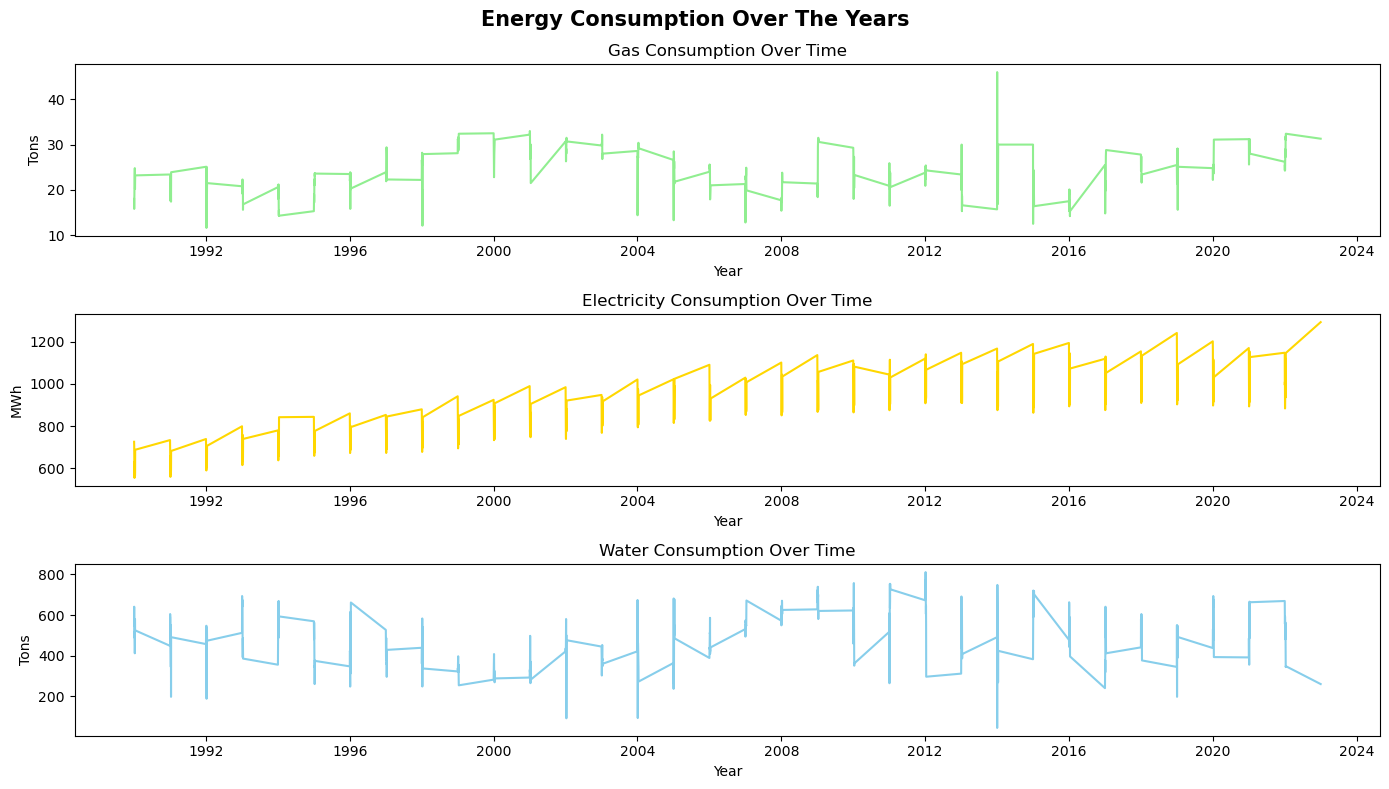

In [75]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8))
axes[0].plot(energy_df.index, energy_df['Gas Consumption (tons)'], color='lightgreen')
axes[0].set_title('Gas Consumption Over Time')
axes[0].set_ylabel('Tons')
axes[0].set_xlabel('Year')

axes[1].plot(energy_df.index, energy_df['Electricity Consumption (MWh)'], color='gold')
axes[1].set_title('Electricity Consumption Over Time')
axes[1].set_ylabel('MWh')
axes[1].set_xlabel('Year')

axes[2].plot(energy_df.index, energy_df['Water Consumption (tons)'], color='skyblue')
axes[2].set_title('Water Consumption Over Time')
axes[2].set_ylabel('Tons')
axes[2].set_xlabel('Year')

plt.suptitle('Energy Consumption Over The Years', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
- This subplot of line chart illustrates the consumption of gas, electricity and water over the years respectively.

- There is a net increase overall for both gas and electricity consumption.
    - Gas consumption shows a gradual upward trend with moderate fluctuations, increasing from roughly 18–20 tons in the early 1990s to around 30+ tons by 2023, indicating a steady rise in usage over time.
    - Electricity consumption exhibits the strongest and most consistent upward trend, rising from approximately 700 MWh in 1990 to about 1300 MWh in 2023, suggesting increasing dependence on electricity over the years.

- In contrast, there is an overall net decrease in water consumption from 1990 to 2023.
    - Decreasing from around 500 tons in 1990 to approximately 250–300 tons by 2023, despite noticeable short-term variability.

- Compared to gas and electricity, water consumption displays higher volatility, indicating greater short-term fluctuations and less stable usage patterns. (more messy patterns)

- The differing trends across the three energy types suggest that energy usage growth is driven primarily by electricity, while water consumption has reduced over time.

## **Visual Representation 2:**

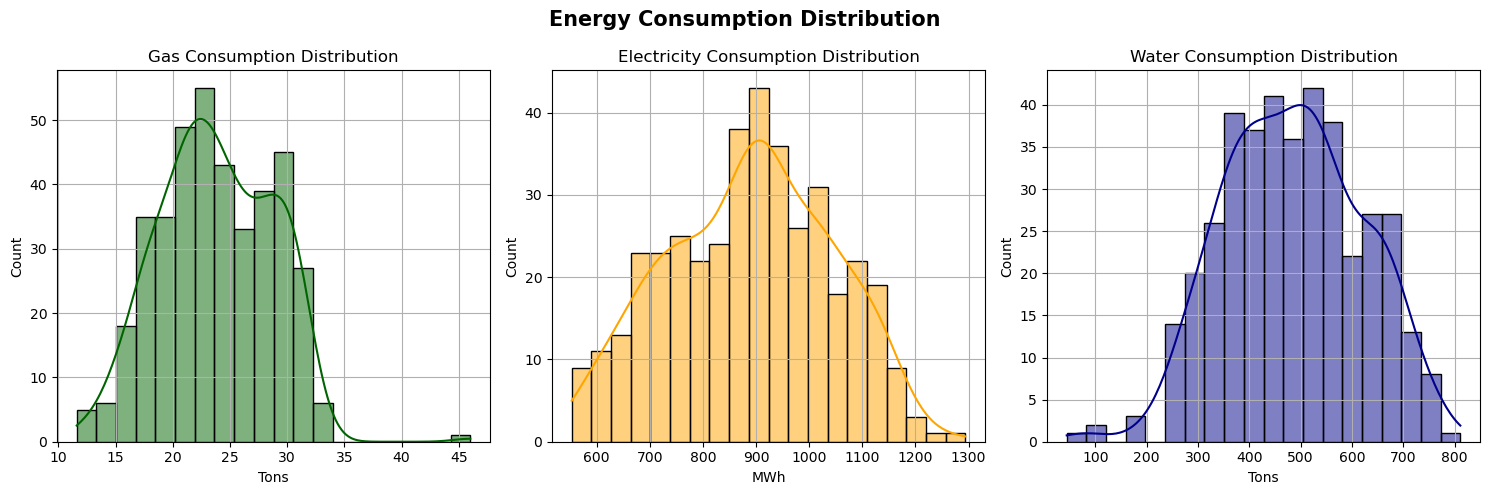

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(energy_df['Gas Consumption (tons)'], bins=20, ax=axes[0], kde=True, color='darkgreen')
axes[0].set_title('Gas Consumption Distribution')
axes[0].set_xlabel('Tons')
axes[0].grid(True)

sns.histplot(energy_df['Electricity Consumption (MWh)'], bins=20, ax=axes[1], kde=True, color='orange')
axes[1].set_title('Electricity Consumption Distribution')
axes[1].set_xlabel('MWh')
axes[1].grid(True)

sns.histplot(energy_df['Water Consumption (tons)'], bins=20, ax=axes[2], kde=True, color='darkblue')
axes[2].set_title('Water Consumption Distribution')
axes[2].set_xlabel('Tons')
axes[2].grid(True)

plt.suptitle('Energy Consumption Distribution', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
- The subplots of histograms illustrate the distribution of energy consumption for gas, electricity and water respectively, highlighting the differences in spread and skewness that was observed in the line chart.

- Skewness:
    - Gas consumption displays a right-skewed distribution, with most observations being concentrated between 20 to 30 tons. and a small number of higher value observation that extend the right tail like the 45 ton indicator on the far right.
    
    - Electricity consumption shows a more moderate right skew but resembles a normally distributed graph due to the exhibition of an almost symmetry-like shape between the left and right sides of the graph as well as its peak being in the centre of the data distribution.
        - Majority of the data is clustered around 800 to 1000 MWh, while there are fewer observations that have higher consumption above 1100Mwh as well as some observations that have a lower consumption than 800 MWh.
    
    - Water consumption exhibits a more left-skewed distribution, with more observations being on the right side of the graph, ranging from about 400 to 700 tons, with fewer observations on the left side that have a lower consumption than 300 tons.
        - Shows that lower water consumption is less frequent but still present.

    - The presence of right-skewness in gas and electricity consumption suggests that mean values may be influenced by higher consumption periods and vice versa for water consumption.

## **Visual Representation 3:** Boxplot

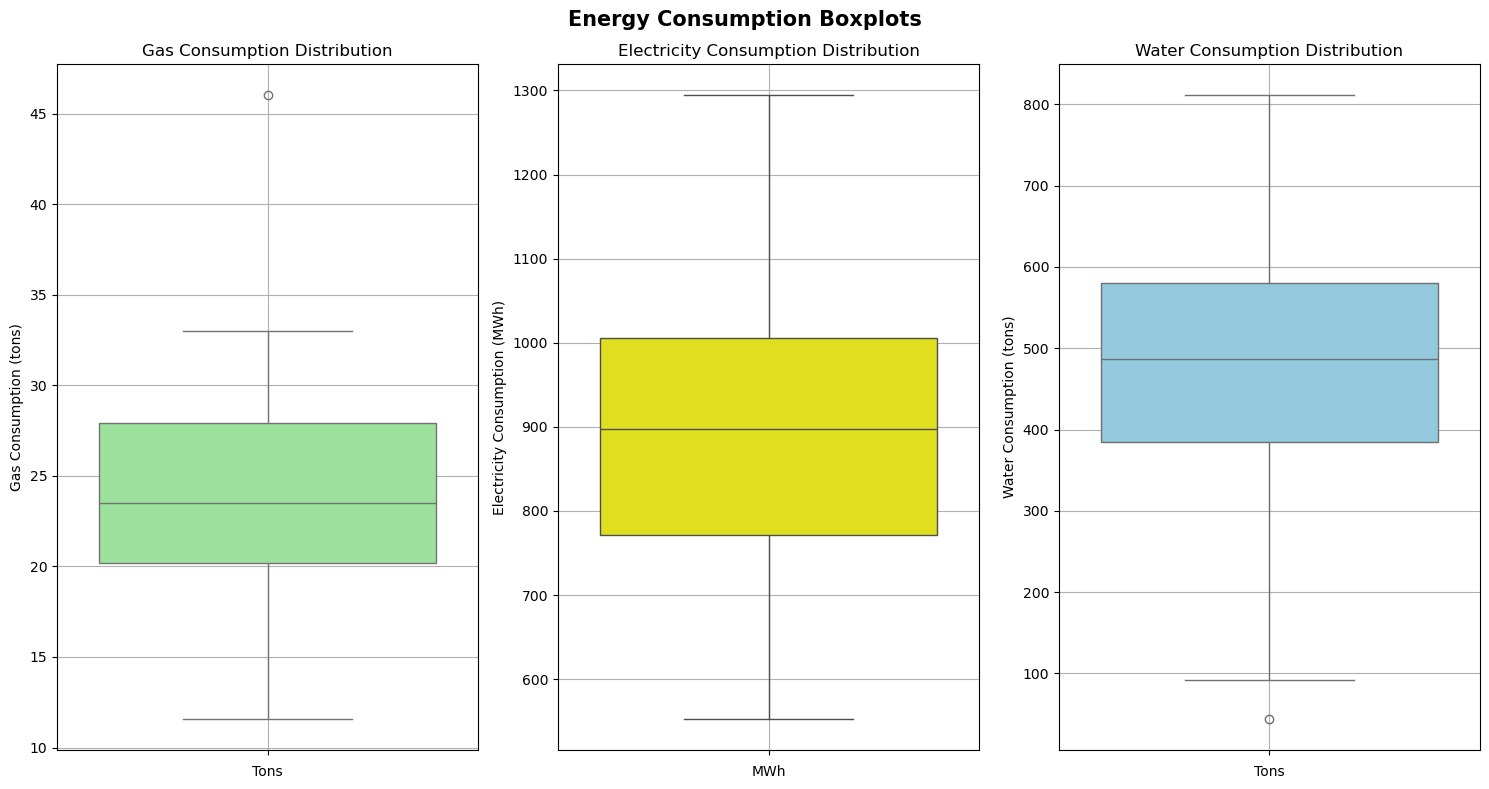

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

sns.boxplot(y=energy_df['Gas Consumption (tons)'], ax=axes[0], color='lightgreen')
axes[0].set_title('Gas Consumption Distribution')
axes[0].set_xlabel('Tons')
axes[0].grid(True)

sns.boxplot(y=energy_df['Electricity Consumption (MWh)'], ax=axes[1], color='yellow')
axes[1].set_title('Electricity Consumption Distribution')
axes[1].set_xlabel('MWh')
axes[1].grid(True)

sns.boxplot(y=energy_df['Water Consumption (tons)'], ax=axes[2], color='skyblue')
axes[2].set_title('Water Consumption Distribution')
axes[2].set_xlabel('Tons')
axes[2].grid(True)

plt.suptitle('Energy Consumption Boxplots', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
These boxplots provide additional insights about the features that were not covered by the histograms.

- ### **Gas:** 
    - The median of gas consumption is closer to Q1 than it is to Q3, indicating that more data is concentrated on the lower side.
    - There is also an outlier at >45 tons, approximately 46-47 tons. Because of this outlier, it extends the right tail, causing the mean to be higher than the median, resulting in a right skew.

- ### **Electricity:**
    - Median is near the centre of the box, almost symmetrical.
    - Exhibits a wider interquartile range, illustrating a higher variability of the data.
    - The whiskers are relatively almost balanced, with the right tail being a little longer, hence it results in the moderate right-skewness of the distribution.
    - There are also no extreme outliers.
    - Indicates that electricity consumption is quite stable with minimal fluctuations, supporting the line chart.

- ### **Water:**
    - Median is slightly closer to Q3 than Q1, indicating that more data is concentrated on the upper side of the distribution.
    - The lower whisker/tail is longer than the upper one, with an anomaly on the lower side, <100 tons.
    - The presence of the anomaly on the lower bound brings the mean down, making it smaller than the median, resulting in a left skew.

- Overall, the spread of electricity and water consumption are much wider than that of gas consumption. Suggesting that the consumption of electricity and water is much wider and spread out, convering a larger numerical range than gas consumption.
    - Showing that there is a greater variance in these 2 energy sources due to the many diverse way they could be used.

---
## **Step 4:** Preprocessing and Feature Engineering

---
## **Step 5:** Model Implementation & Analysis

---
## **Step 6:** Model Evaluation

---
## **Step 7:** Model Improvement **(Hyperparameter Tuning)**

--- 
## **Summary of Part B:**